# НДМ — обучение нейросети с нуля (300 000 эталонов, Numba, Rs/Rsc как входы)

Самостоятельный ML-блокнот со стабильным ядром НДМ. Все важные диапазоны — **в следующей ячейке**, до расчётных функций:

- Диапазон площадей **каждого слоя** $A_{sb}$ и $A_{st}$, см²/м.
- Диапазон толщин $h$, мм.
- Привязки осей каждого слоя: $a_{sb},a_{st}\in[a_{\min},\,0{,}45h]$ по умолчанию; $a_{\min}$ задаётся в мм, коэффициент $0{,}45$ редактируется.
- Минимальный и максимальный процент армирования **для каждого слоя отдельно**: $\rho_{sb}$ и $\rho_{st}$; сумма площадей не используется как критерий процентов.
- Запас по площади $\delta_A$ (по умолчанию 3%). **Усилия $N,M_y$ не изменяются.**
- Редактируемая **матрица классов бетона B15–B60**: согласованные пары $R_b,E_b$.
- Редактируемая **матрица классов арматуры А400 и А500**: согласованные пары $R_s,R_{sc}$.

Расчётная полоса $b=1000$ мм. При толщине $h$ граница по каждому слою равна $A_s=\rho_s[\%]\,h/10$ см²/м. Для каждой толщины фактические ограничения площадей — пересечение абсолютных и процентных пределов. Эталонный подбор учитывает верхний предел с резервом под запас: $A^*_{s,\max}=\min(A_{\max},\rho_{\max}h/10)/(1+\delta_A)$. Затем обучающие метки вычисляются как $A_{sb}^{target}=(1+\delta_A)A_{sb}^*$ и $A_{st}^{target}=(1+\delta_A)A_{st}^*$.

В генераторе новый диапазон привязок **заменяет прежние жёсткие `18…50 мм` и `0,25h`**. Старые веса и датасет для нового диапазона не используются: выборка генерируется заново, сеть обучается с нуля. Границы привязок записываются в файлы датасета и модели.

**Входы:** $N$ (кН/м), $M_y$ (кН·м/м), $R_b,E_b,R_s,R_{sc}$ (МПа), $h,a_{sb},a_{st}$ (мм). **Выходы:** $A_{sb},A_{st}$ (см²/м).

Генерируется новая выборка из 300 000 примеров, сеть обучается с нуля, без загрузки старых весов. **Существующие файлы автоматически не удаляются**; при сохранении нового датасета и весов файлы с теми же именами будут перезаписаны. При необходимости предварительно удали старые файлы самостоятельно.

Зависимости: `pip install numpy numba torch plotly`. Запуск: `Run All`. SciPy не требуется.


Пары $R_b$ и $E_b$ приведены для **тяжёлого бетона**: расчётное сопротивление сжатию первой группы (таблица 6.8) и начальный модуль упругости (таблица 6.11) СП 63.13330.2018. Коэффициенты условий работы, если необходимы, должны учитываться отдельно: матрица содержит базовые табличные значения. Источник: https://base.garant.ru/72230218/ .

**Сталь:** `Rs` и `Rsc` (МПа) — расчётные сопротивления при растяжении и сжатии.
Пары выбираются из `ML_STEEL_MATRIX` в первой ячейке (А400 и А500).
Стандарт: СП 63.13330.2018, табл. 6.14 в редакции Изменения № 1.
Здесь для А500 принято `Rsc=400 МПа` (кратковременное действие).
При необходимости длительных нагрузок следует изменить постановку и набор допустимых пар.

**Порядок 9 входов:** `[N, My, Rb, Eb, h, a_sb, a_st, Rs, Rsc]`.
Остальные условия: `b=1000 мм`, площадь в `см²/м`; запас `ML_MARGIN` прибавляется только к площадям арматуры.
Размерность сети — `17 → 192 → 192 → 192 → 2`; сохраняется класс размера около 300 КиБ.


In [1]:
# =============================================================
# ЕДИНЫЕ НАСТРОЙКИ ОБУЧЕНИЯ НДМ — изменить здесь перед Run All
# =============================================================
# Ширина расчётной полосы фиксирована: b = 1000 мм (1 м).
# Площади в см²/м; толщина и привязки арматуры в мм.

# 1. Диапазон площадей для КАЖДОГО слоя по отдельности:
ML_A_MIN = 0.5                       # см²/м, нижний предел A_sb и A_st
ML_A_MAX = 200.0                      # см²/м, верхний предел A_sb и A_st

# 1а. ТЯЖЁЛЫЙ БЕТОН: связанные пары Rb/Eb по СП 63.13330.2018.
# Столбцы: [класс бетона, Rb (МПа), Eb (МПа)].
# Rb — таблица 6.8, расчётное сопротивление сжатию для I группы;
# Eb — таблица 6.11, начальный модуль упругости тяжёлого бетона.
# При генерации случайно выбирается ОДНА строка — Rb и Eb не независимы.
# Можно удалить строки ненужных классов или добавить другие классы.
ML_CONCRETE_MATRIX = (
    ('B15',  8.5, 24000.0),
    ('B20', 11.5, 27500.0),
    ('B25', 14.5, 30000.0),
    ('B30', 17.0, 32500.0),
    ('B35', 19.5, 34500.0),
    ('B40', 22.0, 36000.0),
    ('B45', 25.0, 37000.0),
    ('B50', 27.5, 38000.0),
    ('B55', 30.0, 39000.0),
    ('B60', 33.0, 39500.0),
)

# 1б. АРМАТУРА: согласованные пары Rs/Rsc по СП 63.13330.2018,
# табл. 6.14 в редакции Изменения № 1, I группа предельных состояний.
# Столбцы: [класс арматуры, Rs (МПа), Rsc (МПа)].
# Для A500 здесь Rsc=400 МПа — при КРАТКОВРЕМЕННОМ действии нагрузки.
# Для длительного действия СП 63 допускает Rsc=435 МПа:
# если нужны такие расчёты, задавайте отдельный режим/обучающую модель.
# Для A400 по Изменению № 1: Rs=Rsc=340 МПа (не 350 МПа старой таблицы).
# Выбирается целая строка: Rs и Rsc не генерируются независимо.
ML_STEEL_MATRIX = (
    ('A500', 435.0, 400.0),
    ('A400', 340.0, 340.0),
)

# Общие фиксированные характеристики стали (для обоих классов):
ML_ES = 200000.0                    # МПа
ML_ES2 = 0.025                      # предельная относительная деформация

# 2. Диапазон толщины оболочки:
ML_H_MIN = 140.0                     # мм
ML_H_MAX = 1000.0                     # мм

# 2а. Привязки осей НИЖНЕЙ и ВЕРХНЕЙ арматуры от ближайшей грани:
# Для каждой толщины h: ML_AS_OFFSET_MIN <= a_sb, a_st <= ML_AS_OFFSET_MAX_H_FRAC*h.
# Общий максимум в долях h, без дополнительного ограничения 50 мм.
ML_AS_OFFSET_MIN = 15.0              # мм, минимум для каждого слоя
ML_AS_OFFSET_MAX_H_FRAC = 0.45       # доля h, максимум для каждого слоя

# 3. Проценты армирования ОТДЕЛЬНО верхнего и нижнего слоя:
# rho_sb = 100 * A_sb[мм²/м] / (1000*h), аналогично rho_st.
# Это НЕ процент суммарной площади (A_sb + A_st)/(b*h).
ML_RHO_MIN_PCT = 0.01                # % — минимум каждого слоя
ML_RHO_MAX_PCT = 10.00                # % — максимум каждого слоя

# 4. Запас ПО ПЛОЩАДЯМ, НЕ ПО УСИЛИЯМ:
# Y_target = (1 + ML_MARGIN) * Y_reference, для каждого слоя.
ML_MARGIN = 0.03                     # 3%; менять здесь

# 5. Датасет и обучение с нуля (старые файлы код НЕ удаляет):
ML_SEED = 20261030
ML_N_SAMPLES = 500_000
ML_GRID, ML_SEEDS, ML_ITERS = 61, 6, 150
ML_DATA_FILE = 'ndm_dataset_300k.npz'
ML_MODEL_FILE = 'ndm_mlp_300kb.npz'
ML_TRAIN_EPOCHS = 220
ML_TRAIN_PATIENCE = 30
ML_BATCH_SIZE = 512
ML_TRAIN_LR = 1.0e-3

# Связь между процентом армирования и площадью для b=1000 мм:
# A[см²/м] = rho[%] * h[мм] / 10.
# Для эталонов верхний предел дополнительно делится на 1+ML_MARGIN,
# чтобы ПОСЛЕ запаса целевые A_sb и A_st не превысили лимиты.


In [2]:
import numpy as np
from pathlib import Path
import sys
print('Python:',sys.version.split()[0])
try:
    import numba, torch
except ImportError as e:
    raise RuntimeError('Установи библиотеки командой: pip install numpy numba torch plotly') from e
print('Numba:',numba.__version__, '| PyTorch:',torch.__version__, '| CUDA:',torch.cuda.is_available())
print('Рабочая директория:',Path.cwd())

Python: 3.12.3
Numba: 0.63.1 | PyTorch: 2.14.1+cu130 | CUDA: False
Рабочая директория: /home/admin/нейросети/НДМ


## 1. Стабильное ядро НДМ (Python)

In [3]:
"""Extracted stable NDM forward model, no experimental optimizers. Units: N, N*mm, mm, MPa, mm2."""
import numpy as np
from dataclasses import dataclass

@dataclass(frozen=True)
class Concrete:
    Rc: float
    Rt: float
    E: float = 32500.0
    eb0: float = 0.002
    eb2: float = 0.0035
    et0: float = 0.0001
    et2: float = 0.00015

@dataclass(frozen=True)
class Steel:
    Rst: float
    Rsc: float
    E: float = 200000.0
    eult: float = 0.025

@dataclass(frozen=True)
class Section:
    b: float = 140.0
    h: float = 200.0
    a_bot: float = 25.0
    a_top: float = 25.0
    @property
    def zb(self): return -self.h/2 + self.a_bot
    @property
    def zt(self): return self.h/2 - self.a_top
    @property
    def d(self): return self.zt-self.zb

CONC_I = Concrete(17.0, 1.15)
CONC_II = Concrete(22.0, 1.75)
STEEL_I = Steel(435.0,400.0)  # Только значение по умолчанию; генератор использует выбранную строку ML_STEEL_MATRIX.
STEEL_II = Steel(500.0,500.0)
SEC = Section()

def concrete_segments(c: Concrete, include_tension: bool):
    """(branch, strain_low, strain_high, alpha, beta) for sigma=alpha*strain+beta."""
    eb1 = 0.6*c.Rc/c.E
    cb = 0.4*c.Rc/(c.eb0-eb1)
    parts = [
        ('Плато сжатия', -c.eb2, -c.eb0, 0.0, -c.Rc),
        ('Переходное сжатие', -c.eb0, -eb1, cb, -0.6*c.Rc+cb*eb1),
        ('Упругое сжатие', -eb1, 0.0, c.E, 0.0),
    ]
    if include_tension:
        et1 = 0.6*c.Rt/c.E
        ct = 0.4*c.Rt/(c.et0-et1)
        parts += [
            ('Упругое растяжение', 0.0, et1, c.E, 0.0),
            ('Переходное растяжение', et1, c.et0, ct, 0.6*c.Rt-ct*et1),
            ('Плато растяжения', c.et0, c.et2, 0.0, c.Rt),
        ]
    return parts

def stress_concrete(eps: float, c: Concrete, tension=False):
    """Only call inside admissible concrete deformation range."""
    if eps >= 0 and not tension:
        return 0.0
    if eps < -c.eb2-1e-12 or (tension and eps > c.et2+1e-12):
        raise ValueError('Деформация бетона выходит за пределы выбранной диаграммы')
    for _, left, right, alpha, beta in concrete_segments(c,tension):
        if left-1e-12 <= eps <= right+1e-12:
            return alpha*eps+beta
    if not tension and eps >= 0: return 0.0
    raise ValueError(f'Недопустимая деформация: {eps}')

def stress_steel(eps: float, s:Steel):
    if abs(eps)>s.eult+1e-12:
        raise ValueError('Предельная деформация арматуры превышена')
    return min(s.E*eps,s.Rst) if eps>=0 else -min(-s.E*eps,s.Rsc)

def concrete_resultants(e0,k,c:Concrete,sec:Section=SEC,tension=False,details=False):
    """Точные N_b, M_b (Н, Н·мм) кусочно-линейной модели."""
    if abs(k*sec.h)<1e-13:
        sig=stress_concrete(e0,c,tension)
        result=(sec.b*sec.h*sig,0.0)
        if details:
            return (*result, [dict(Участок='Равномерная деформация',z1=-sec.h/2,z2=sec.h/2, sigma1=sig,sigma2=sig,dN=result[0],dM=0)])
        return result
    n,m=0.0,0.0
    contributions=[]
    for name,el,er,alpha,beta in concrete_segments(c,tension):
        za=(el-e0)/k; zb=(er-e0)/k
        z1=max(-sec.h/2, min(za,zb))
        z2=min( sec.h/2, max(za,zb))
        if z2<=z1+1e-12: continue
        sig1=alpha*(e0+k*z1)+beta
        sig2=alpha*(e0+k*z2)+beta
        dz=z2-z1
        dN=sec.b*dz*(sig1+sig2)/2
        dM=-sec.b*dz*((2*z1+z2)*sig1+(z1+2*z2)*sig2)/6
        n+=dN; m+=dM
        contributions.append(dict(Участок=name,z1=z1,z2=z2,sigma1=sig1,sigma2=sig2,dN=dN,dM=dM))
    if details: return n,m,contributions
    return n,m

def beta_concrete(k:float,sec:Section=SEC,c:Concrete=CONC_I):
    t=abs(k)*sec.h/2
    if t <= c.eb2/2:
        return t-(c.eb0+np.sqrt(c.eb0**2+8*(c.eb2-c.eb0)*t))/2
    return t-c.eb2

def beta_crack(k:float,sec:Section=SEC,c:Concrete=CONC_II):
    t=abs(k)*sec.h/2
    if t<=c.et2/2:
        return -t+(c.et0+np.sqrt(c.et0**2+8*(c.et2-c.et0)*t))/2
    return c.et2-t

def k_limits(sec:Section=SEC,c:Concrete=CONC_I,s:Steel=STEEL_I):
    return (-(c.eb2+s.eult)/(sec.h-sec.a_bot), (c.eb2+s.eult)/(sec.h-sec.a_top))

def strain_bounds(k,sec:Section=SEC,c:Concrete=CONC_I,s:Steel=STEEL_I):
    lower=max(beta_concrete(k,sec,c),-s.eult-k*sec.zb,-s.eult-k*sec.zt)
    upper=min(s.eult-k*sec.zb,s.eult-k*sec.zt)
    return lower,upper

def resultants(e0,k,As_bot,As_top,sec:Section=SEC,c:Concrete=CONC_I,s:Steel=STEEL_I,tension=False):
    nb,mb=concrete_resultants(e0,k,c,sec,tension)
    eb=e0+k*sec.zb; et=e0+k*sec.zt
    qb=stress_steel(eb,s)-stress_concrete(eb,c,tension)
    qt=stress_steel(et,s)-stress_concrete(et,c,tension)
    return nb+As_bot*qb+As_top*qt, mb-As_bot*qb*sec.zb-As_top*qt*sec.zt

def candidate_areas(e0,k,N,M,sec:Section=SEC,c:Concrete=CONC_I,s:Steel=STEEL_I):
    nb,mb=concrete_resultants(e0,k,c,sec,False)
    eb=e0+k*sec.zb; et=e0+k*sec.zt
    qb=stress_steel(eb,s)-stress_concrete(eb,c,False)
    qt=stress_steel(et,s)-stress_concrete(et,c,False)
    p=sec.zt*(N-nb)+(M-mb)
    q=-sec.zb*(N-nb)-(M-mb)
    if abs(qb)<1e-8 or abs(qt)<1e-8:
        return None  # singular cases require independent linear feasibility solver
    return p/(sec.d*qb), q/(sec.d*qt)

# Independent quadrature check (only inside admissible concrete range):
def concrete_quad(e0,k,c=CONC_I,sec=SEC,tension=False):
    levels=[e for _,l,r,_,_ in concrete_segments(c,tension) for e in (l,r)]
    zs=[(e-e0)/k for e in levels] if abs(k)>1e-15 else []
    pts=sorted(set(z for z in zs if -sec.h/2 < z < sec.h/2))
    f=lambda z: stress_concrete(e0+k*z,c,tension)
    # Независимая составная 8-точечная квадратура Гаусса — без SciPy.
    nodes,weights=np.polynomial.legendre.leggauss(8)
    edges=[-sec.h/2]+pts+[sec.h/2]
    n=m=0.0
    for zl,zr in zip(edges[:-1],edges[1:]):
        zz=(zl+zr)/2+(zr-zl)/2*nodes
        ss=np.array([f(float(z)) for z in zz])
        n+=sec.b*(zr-zl)/2*np.dot(weights,ss)
        m-=sec.b*(zr-zl)/2*np.dot(weights,zz*ss)
    return n,m

def make_section(h, asb, ast, b=1000.0):
    if not (h>0 and b>0 and 0<=asb<h/2 and 0<=ast<h/2):
        raise ValueError('Invalid section geometry')
    return Section(float(b),float(h),float(asb),float(ast))

def make_concrete(Rb,Eb,eb0=0.002,eb2=0.0035):
    if not (Rb>0 and Eb>0 and eb2>=eb0>0): raise ValueError('Invalid concrete params')
    return Concrete(Rc=float(Rb),Rt=0.,E=float(Eb),eb0=eb0,eb2=eb2)

def predict_resultants(e0,k,asb_cm2,ast_cm2,N_kN_m=None,My_kNm_m=None,*,Rb,Eb,h,a_sb,a_st,Rs=435.,Rsc=400.,Es=200000.,es2=.025,eb0=.002,eb2=.0035):
    sec=make_section(h,a_sb,a_st)
    c=make_concrete(Rb,Eb,eb0,eb2)
    s=Steel(Rs,Rsc,Es,es2)
    return resultants(e0,k,100*asb_cm2,100*ast_cm2,sec,c,s,False)


## 2. Ускоренный учитель (Numba)

In [4]:
# ========== Stable NDM teacher: accelerated copies of the analytical model ==========
# Input: [N (kN/m), My (kN*m/m), Rb (MPa), Eb (MPa), h, a_sb, a_st (mm), Rs (MPa), Rsc (MPa)].
# Internal reference stripe: b=1000 mm, N in N, M in N*mm, A in mm^2.
from numba import njit, prange
import numpy as np
import time

ML_B = 1000.0
# ML_ES and ML_ES2 are defined in the common settings cell.
# Rs and Rsc are now supplied per sample, never constants.
ML_EB0, ML_EB2 = 0.002, 0.0035

@njit(cache=False)
def _ml_training_area_limits(h, amin, amax, rho_min_pct, rho_max_pct, margin):
    """Area bounds (cm²/m) for EACH layer, b=1000 mm, before safety margin.

    Choose a reference upper bound such that multiplying by (1+margin)
    cannot violate either absolute or relative area limits.
    """
    min_layer=max(amin, rho_min_pct*h/10.0)
    max_layer=min(amax, rho_max_pct*h/10.0)
    return min_layer, max_layer/(1.0+margin)

@njit(cache=False)
def _ml_concrete_stress(e, rb, eb, eb0):
    if e >= 0.0:
        return 0.0
    eb1=0.6*rb/eb
    if e <= -eb0:
        return -rb
    if e <= -eb1:
        slope=0.4*rb/(eb0-eb1)
        return slope*e-0.6*rb+slope*eb1
    return eb*e

@njit(cache=False)
def _ml_steel_stress(e,rs,rsc):
    if e >= 0.0:
        return min(ML_ES*e, rs)
    return -min(-ML_ES*e, rsc)

@njit(cache=False)
def _ml_concrete_nm(e0,k,rb,eb,h):
    # Exact integration of the same three compression segments as the stable NDM core.
    eb1=0.6*rb/eb
    slope=0.4*rb/(ML_EB0-eb1)
    levels=(-ML_EB2,-ML_EB0,-eb1,0.0)
    slopes=(0.0,slope,eb)
    consts=(-rb,-0.6*rb+slope*eb1,0.0)
    half=0.5*h
    if abs(k*h)<1e-13:
        return ML_B*h*_ml_concrete_stress(e0,rb,eb,ML_EB0), 0.0
    nb=0.0;mb=0.0
    for i in range(3):
        a=(levels[i]-e0)/k
        b=(levels[i+1]-e0)/k
        z1=max(-half,min(a,b))
        z2=min(half,max(a,b))
        if z2<=z1+1e-12:
            continue
        sig1=slopes[i]*(e0+k*z1)+consts[i]
        sig2=slopes[i]*(e0+k*z2)+consts[i]
        dz=z2-z1
        nb+=ML_B*dz*0.5*(sig1+sig2)
        mb-=ML_B*dz*((2*z1+z2)*sig1+(z1+2*z2)*sig2)/6.0
    return nb,mb

@njit(cache=False)
def _ml_bounds(k,rb,eb,h,ab,at):
    zb=-0.5*h+ab; zt=0.5*h-at
    t=abs(k)*0.5*h
    if t<=0.5*ML_EB2:
        bc=t-0.5*(ML_EB0+np.sqrt(ML_EB0**2+8*(ML_EB2-ML_EB0)*t))
    else:
        bc=t-ML_EB2
    low=max(bc,-ML_ES2-k*zb,-ML_ES2-k*zt)
    high=min(ML_ES2-k*zb,ML_ES2-k*zt)
    return low,high

@njit(cache=False)
def _ml_nm(e0,k,ab_cm,at_cm,rb,eb,h,ab,at,rs,rsc):
    nb,mb=_ml_concrete_nm(e0,k,rb,eb,h)
    zb=-0.5*h+ab;zt=0.5*h-at
    eb_ = e0+k*zb; et_ = e0+k*zt
    qb=_ml_steel_stress(eb_,rs,rsc)-_ml_concrete_stress(eb_,rb,eb,ML_EB0)
    qt=_ml_steel_stress(et_,rs,rsc)-_ml_concrete_stress(et_,rb,eb,ML_EB0)
    N=nb+100.0*ab_cm*qb+100.0*at_cm*qt
    M=mb-100.0*ab_cm*qb*zb-100.0*at_cm*qt*zt
    return N,M

@njit(cache=False)
def _ml_areas(e0,k,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax):
    nb,mb=_ml_concrete_nm(e0,k,rb,eb,h)
    zb=-0.5*h+ab; zt=0.5*h-at; d=zt-zb
    eb_ = e0+k*zb; et_ = e0+k*zt
    qb=_ml_steel_stress(eb_,rs,rsc)-_ml_concrete_stress(eb_,rb,eb,ML_EB0)
    qt=_ml_steel_stress(et_,rs,rsc)-_ml_concrete_stress(et_,rb,eb,ML_EB0)
    if abs(qb)<1e-8 or abs(qt)<1e-8:
        return np.inf, np.nan,np.nan
    bot=(zt*(N-nb)+(M-mb))/(d*qb*100.0)
    top=(-zb*(N-nb)-(M-mb))/(d*qt*100.0)
    if not (np.isfinite(bot) and np.isfinite(top)):
        return np.inf,np.nan,np.nan
    if bot<amin-1e-9 or bot>amax+1e-9 or top<amin-1e-9 or top>amax+1e-9:
        return np.inf,bot,top
    return bot+top,bot,top

@njit(cache=False)
def _ml_eval_uv(u,v,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax):
    if u<0.0 or u>1.0 or v<0.0 or v>1.0:
        return np.inf,np.nan,np.nan,0.0,0.0
    kl=-(ML_EB2+ML_ES2)/(h-ab)
    kr= (ML_EB2+ML_ES2)/(h-at)
    k=kl+v*(kr-kl)
    low,high=_ml_bounds(k,rb,eb,h,ab,at)
    if low>high+1e-13:
        return np.inf,np.nan,np.nan,0.0,0.0
    e0=low+u*max(0.0,high-low)
    obj,bot,top=_ml_areas(e0,k,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
    return obj,bot,top,e0,k

@njit(cache=False)
def _ml_teacher_one(row,ngrid=41,n_seeds=5,maxiter=120,amin=ML_A_MIN,amax=ML_A_MAX):
    N=row[0]*1e3;M=row[1]*1e6
    rb=row[2];eb=row[3];h=row[4];ab=row[5];at=row[6];rs=row[7];rsc=row[8]
    bu=np.empty(n_seeds,dtype=np.float64)
    bv=np.empty(n_seeds,dtype=np.float64)
    bf=np.empty(n_seeds,dtype=np.float64)
    for j in range(n_seeds):
        bf[j]=np.inf
    for i in range(ngrid):
        u=i/(ngrid-1.0)
        for j in range(ngrid):
            v=j/(ngrid-1.0)
            val,_,_,_,_=_ml_eval_uv(u,v,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
            if val < bf[n_seeds-1]:
                pos=n_seeds-1
                while pos>0 and val<bf[pos-1]:
                    bf[pos]=bf[pos-1];bu[pos]=bu[pos-1];bv[pos]=bv[pos-1];pos-=1
                bf[pos]=val;bu[pos]=u;bv[pos]=v
    if not np.isfinite(bf[0]):
        return np.nan,np.nan,np.nan,np.nan,np.nan,np.inf,0
    best_obj=np.inf;best_bot=np.nan;best_top=np.nan;best_e=np.nan;best_k=np.nan
    directions=((1.0,0.0),(-1.0,0.0),(0.0,1.0),(0.0,-1.0),
                (0.7071067811865476,0.7071067811865476),
                (0.7071067811865476,-0.7071067811865476),
                (-0.7071067811865476,0.7071067811865476),
                (-0.7071067811865476,-0.7071067811865476))
    for seed in range(n_seeds):
        if not np.isfinite(bf[seed]): continue
        u=bu[seed];v=bv[seed];f=bf[seed];step=0.045
        for it in range(maxiter):
            improved=False
            nu=u;nv=v;nf=f
            for dx,dy in directions:
                uu=u+step*dx;vv=v+step*dy
                val,_,_,_,_=_ml_eval_uv(uu,vv,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
                if val<nf-1e-11:
                    nf=val;nu=uu;nv=vv;improved=True
            # Tangential searches close to active area boundaries (same logic as stable baseline)
            cur,a_b,a_t,_,_=_ml_eval_uv(u,v,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
            for act in range(2):
                a=a_b if act==0 else a_t
                if not (np.isfinite(a) and min(abs(a-amin),abs(a-amax))<5.0+200*step):
                    continue
                dh=1e-5
                _,b1,t1,_,_=_ml_eval_uv(min(1.0,u+dh),v,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
                _,b2,t2,_,_=_ml_eval_uv(max(0.0,u-dh),v,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
                _,b3,t3,_,_=_ml_eval_uv(u,min(1.0,v+dh),N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
                _,b4,t4,_,_=_ml_eval_uv(u,max(0.0,v-dh),N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
                # _ml_eval_uv returns area estimates even when limits are violated.
                g0=((b1-b2) if act==0 else (t1-t2))/(min(1.0,u+dh)-max(0.0,u-dh))
                g1=((b3-b4) if act==0 else (t3-t4))/(min(1.0,v+dh)-max(0.0,v-dh))
                length=np.sqrt(g0*g0+g1*g1)
                if np.isfinite(length) and length>1e-10:
                    for sgn in (-1.0,1.0):
                        uu=u+sgn*step*(-g1)/length
                        vv=v+sgn*step*g0/length
                        val,_,_,_,_=_ml_eval_uv(uu,vv,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
                        if val<nf-1e-11:
                            nf=val;nu=uu;nv=vv;improved=True
            if improved:
                u=nu;v=nv;f=nf
            else:
                step*=0.5
                if step<1e-7:break
        obj,bot,top,e,k=_ml_eval_uv(u,v,N,M,rb,eb,h,ab,at,rs,rsc,amin,amax)
        if obj<best_obj:
            best_obj=obj;best_bot=bot;best_top=top;best_e=e;best_k=k
    return best_bot,best_top,best_e,best_k,best_obj,best_obj,1

@njit(parallel=True,cache=False)
def _ml_label_batch(X,ngrid,nseeds,maxiter,amin,amax,rho_min_pct,rho_max_pct,margin):
    count=X.shape[0]
    Y=np.empty((count,2),dtype=np.float64)
    states=np.empty((count,2),dtype=np.float64)
    success=np.zeros(count,dtype=np.bool_)
    for i in prange(count):
        lo,hi=_ml_training_area_limits(X[i,4],amin,amax,rho_min_pct,rho_max_pct,margin)
        if lo>hi:
            bot=np.nan;top=np.nan;e=np.nan;k=np.nan;obj=np.inf;ok=0
        else:
            bot,top,e,k,obj,unused,ok=_ml_teacher_one(X[i],ngrid,nseeds,maxiter,lo,hi)
        Y[i,0]=bot;Y[i,1]=top
        states[i,0]=e;states[i,1]=k
        success[i]=(ok==1 and np.isfinite(obj))
    return Y,states,success

def ml_numba_selftest(repeats=120,seed=2201):
    """Compare accelerated N,M against stable pure-Python core for random admissible states."""
    rr=np.random.default_rng(seed)
    max_abs_n=max_abs_m=0.
    for _ in range(repeats):
        _,rb,eb=ML_CONCRETE_MATRIX[int(rr.integers(len(ML_CONCRETE_MATRIX)))];h=rr.uniform(ML_H_MIN,ML_H_MAX)
        _,rs,rsc=ML_STEEL_MATRIX[int(rr.integers(len(ML_STEEL_MATRIX)))];steel=Steel(rs,rsc,ML_ES,ML_ES2)
        ab=rr.uniform(ML_AS_OFFSET_MIN, ML_AS_OFFSET_MAX_H_FRAC*h)
        at=rr.uniform(ML_AS_OFFSET_MIN, ML_AS_OFFSET_MAX_H_FRAC*h)
        s=make_section(h,ab,at);c=make_concrete(rb,eb)
        kl,kr=k_limits(s,c,steel)
        k=rr.uniform(.85*kl,.85*kr)
        lo,hi=strain_bounds(k,s,c,steel)
        if lo>hi: continue
        e=rr.uniform(lo,hi)
        aa=rr.uniform(2,40,2)
        n0,m0=resultants(e,k,100*aa[0],100*aa[1],s,c,steel)
        n1,m1=_ml_nm(e,k,aa[0],aa[1],rb,eb,h,ab,at,rs,rsc)
        max_abs_n=max(max_abs_n,abs(n0-n1));max_abs_m=max(max_abs_m,abs(m0-m1))
        if not (np.isclose(n0,n1,rtol=1e-9,atol=1e-5) and np.isclose(m0,m1,rtol=1e-9,atol=1e-3)):
            raise AssertionError(f'Disagreement: {n0,m0} / {n1,m1}')
    print(f'Numba vs stable core ({repeats} states): max |ΔN|={max_abs_n:.3g} Н, max |ΔM|={max_abs_m:.3g} Н·мм')

# Physical data generator: states sampled inside strain_bounds, realistic variety of load cases.
def ml_sample_inputs(n,seed=20261027,amin=ML_A_MIN,amax=ML_A_MAX,
                     rho_min_pct=ML_RHO_MIN_PCT,rho_max_pct=ML_RHO_MAX_PCT,
                     margin=ML_MARGIN):
    rng=np.random.default_rng(seed)
    X=np.empty((n,9),dtype=np.float64)
    for i in range(n):
        _,rb,eb=ML_CONCRETE_MATRIX[int(rng.integers(len(ML_CONCRETE_MATRIX)))];_,rs,rsc=ML_STEEL_MATRIX[int(rng.integers(len(ML_STEEL_MATRIX)))];steel=Steel(rs,rsc,ML_ES,ML_ES2)
        h=rng.uniform(ML_H_MIN,ML_H_MAX)
        ab=rng.uniform(ML_AS_OFFSET_MIN, ML_AS_OFFSET_MAX_H_FRAC*h)
        at=rng.uniform(ML_AS_OFFSET_MIN, ML_AS_OFFSET_MAX_H_FRAC*h)
        s=make_section(h,ab,at); c=make_concrete(rb,eb)
        kl,kr=k_limits(s,c,steel)
        # Mixed regimes: concrete compression, bending, predominantly steel tension.
        mode=i%5
        if mode==0: k=rng.uniform(-.95,.95)*max(-kl,kr)
        elif mode==1: k=rng.uniform(-.45,.45)*max(-kl,kr)
        elif mode==2: k=rng.uniform(-.9,-.08)*(-kl)
        elif mode==3: k=rng.uniform(.08,.9)*kr
        else: k=rng.uniform(-.15,.15)*max(-kl,kr)
        k=np.clip(k,kl,kr)
        low,high=strain_bounds(k,s,c,steel)
        if high<low:
            # Geometric curvature bounds may include a thin inadmissible tip
            # with the nonlinear compression constraint. Scale towards zero.
            for _ in range(40):
                k*=0.90
                low,high=strain_bounds(k,s,c,steel)
                if low<=high: break
            if high<low: raise RuntimeError('Empty admissible interval after reduction')
        v=rng.beta(0.8,0.8) if (i%3==0) else rng.uniform(0.0,1.0)
        e=low+v*(high-low)
        # Independent bounds for A_sb and A_st, not their sum.
        # Reference maximum reserves space for the (1+margin) ML label.
        area_lo,area_hi=_ml_training_area_limits(
            h,amin,amax,rho_min_pct,rho_max_pct,margin)
        if area_lo>=area_hi:
            raise ValueError('Пустой диапазон A_s: измени min/max площади, % или h.')
        a1=np.exp(rng.uniform(np.log(area_lo),np.log(area_hi)))
        a2=np.exp(rng.uniform(np.log(area_lo),np.log(area_hi)))
        N,M=resultants(e,k,100*a1,100*a2,s,c,steel)
        X[i]=[N/1000.,M/1e6,rb,eb,h,ab,at,rs,rsc]
    return X

def ml_generate_dataset(n=ML_N_SAMPLES,seed=ML_SEED,ngrid=41,nseeds=5,maxiter=100,
                        amin=ML_A_MIN,amax=ML_A_MAX,batch=2048,save_path=ML_DATA_FILE,
                        margin=ML_MARGIN,rho_min_pct=ML_RHO_MIN_PCT,
                        rho_max_pct=ML_RHO_MAX_PCT):
    """Numba teacher + retries at larger grid for failures, write reproducible compressed dataset."""
    ml_numba_selftest(repeats=30)
    if not (0.0<=rho_min_pct<rho_max_pct<=100.0 and amin>0.0 and amax>amin
            and 0<=margin and ML_H_MIN>0.0 and ML_H_MAX>ML_H_MIN):
        raise ValueError('Некорректные пределы площадей, толщин, процентов или запаса.')
    if not (0 <= ML_AS_OFFSET_MIN < ML_H_MIN*ML_AS_OFFSET_MAX_H_FRAC
            and 0 < ML_AS_OFFSET_MAX_H_FRAC < 0.5):
        raise ValueError('Пустой/некорректный диапазон привязок: минимум в мм должен быть меньше max_frac*h_min; max_frac<0.5.')
    for h_edge in (ML_H_MIN,ML_H_MAX):
        lo,hi=_ml_training_area_limits(h_edge,amin,amax,rho_min_pct,rho_max_pct,margin)
        if lo>=hi:
            raise ValueError(f'Для толщины h={h_edge:g} мм нет допустимых A_s с учётом запаса.')
    if not ML_STEEL_MATRIX:
        raise ValueError('Матрица классов стали ML_STEEL_MATRIX пуста.')
    if not ML_CONCRETE_MATRIX:
        raise ValueError('Матрица классов бетона ML_CONCRETE_MATRIX пуста.')
    rng=np.random.default_rng(seed)
    xs=[];ys=[];states=[];total=0
    start=time.perf_counter()
    while total<n:
        size=min(batch,max(n-total+max(batch//8,1),batch))
        x=ml_sample_inputs(size,int(rng.integers(0,2**31)),amin,amax,
                           rho_min_pct,rho_max_pct,margin)
        yy,st,ok=_ml_label_batch(x,ngrid,nseeds,maxiter,amin,amax,
                                 rho_min_pct,rho_max_pct,margin)
        # Rescue states that are feasible by construction, but missed by the initial grid.
        failed=np.flatnonzero(~ok)
        if len(failed):
            y2,s2,o2=_ml_label_batch(x[failed],max(ngrid,71),nseeds,maxiter+50,
                                     amin,amax,rho_min_pct,rho_max_pct,margin)
            yy[failed]=y2;st[failed]=s2;ok[failed]=o2
        ix=np.flatnonzero(ok)[:n-total]
        if len(ix):
            xs.append(x[ix]);ys.append(yy[ix]);states.append(st[ix]);total+=len(ix)
        print(f'Данные: {total}/{n} | в партии {sum(ok)}/{size} | {time.perf_counter()-start:.1f} с',flush=True)
        if len(ix)==0:
            raise RuntimeError('Teacher cannot find admissible solutions. Review sampling and limits.')
    X=np.vstack(xs);Y=np.vstack(ys);S=np.vstack(states)
    # The margin is applied only to the *area labels*, never to N or M.
    Y_target = Y * (1.0 + margin)  # full margin; no clipping needed due to teacher limits
    # Independent force equilibrium and strain checks on the teacher outputs.
    ml_audit_dataset(X,Y,S,seed=seed)
    np.savez_compressed(save_path,X=X.astype(np.float64),Y=Y.astype(np.float64),
                        Y_target=Y_target.astype(np.float64),margin=np.float64(margin),
                        states=S.astype(np.float64),seed=np.int64(seed),
                        amin=np.float64(amin),amax=np.float64(amax),
                        h_min=np.float64(ML_H_MIN),h_max=np.float64(ML_H_MAX),
                        as_offset_min_mm=np.float64(ML_AS_OFFSET_MIN),
                        as_offset_max_h_frac=np.float64(ML_AS_OFFSET_MAX_H_FRAC),
                        rho_min_pct=np.float64(rho_min_pct),
                        rho_max_pct=np.float64(rho_max_pct),
                        steel_classes=np.asarray([r[0] for r in ML_STEEL_MATRIX],dtype='U8'),
                        steel_Rs_Rsc_MPa=np.asarray([r[1:] for r in ML_STEEL_MATRIX],dtype=np.float64),
                        Es_MPa=np.float64(ML_ES),es2=np.float64(ML_ES2),
                        input_columns=np.asarray(['N_kN_m','My_kNm_m','Rb_MPa','Eb_MPa',
                                                  'h_mm','asb_mm','ast_mm','Rs_MPa','Rsc_MPa'],dtype='U16'),
                        concrete_classes=np.asarray([r[0] for r in ML_CONCRETE_MATRIX],dtype='U8'),
                        concrete_Rb_Eb_MPa=np.asarray([r[1:] for r in ML_CONCRETE_MATRIX],dtype=np.float64))
    print(f'Сохранена выборка: {save_path} | {len(X)} строк | {time.perf_counter()-start:.1f} с')
    return X,Y,Y_target,S

def ml_audit_dataset(X,Y,S,seed=0,limit=2000):
    X=np.asarray(X,dtype=np.float64);Y=np.asarray(Y,dtype=np.float64)
    rng=np.random.default_rng(seed)
    sample=rng.choice(len(X),size=min(limit,len(X)),replace=False)
    err_n=0.;err_m=0.;bad=0
    for i in sample:
        n,m,rb,eb,h,ab,at,rs,rsc=X[i]
        y1,y2=Y[i];e,k=S[i]
        nr,mr=_ml_nm(e,k,y1,y2,rb,eb,h,ab,at,rs,rsc)
        lo,hi=_ml_bounds(k,rb,eb,h,ab,at)
        if not (lo-1e-9<=e<=hi+1e-9):bad+=1
        pmin=max(ML_A_MIN, ML_RHO_MIN_PCT*h/10.0)
        pmax=min(ML_A_MAX, ML_RHO_MAX_PCT*h/10.0)
        if (y1<pmin-1e-7 or y2<pmin-1e-7 or
            y1*(1+ML_MARGIN)>pmax+1e-7 or y2*(1+ML_MARGIN)>pmax+1e-7):bad+=1
        err_n=max(err_n,abs(nr-1000*n));err_m=max(err_m,abs(mr-1e6*m))
    assert bad==0 and err_n<0.1 and err_m<100., (bad,err_n,err_m)
    print(f'Аудит {len(sample)} эталонов: max |ΔN|={err_n:.4g} Н, max |ΔM|={err_m:.4g} Н·мм')


## 3. Признаки, сеть и функции проверки

In [5]:
# ========== ML: 17 engineered features from 9 physical inputs; 3x192 float32 MLP ==========
# Dependencies for training: NumPy + PyTorch; Numba only for generating teacher labels.
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

ML_HIDDEN=192

def ml_features(raw9):
    """9 physical inputs -> 17 features. Input order: N, My, Rb, Eb, h, asb, ast, Rs, Rsc."""
    x=np.asarray(raw9,dtype=np.float64).reshape(-1,9)
    N,M,rb,eb,h,ab,at,rs,rsc=x.T
    if not (np.isfinite(x).all() and (rb>0).all() and (eb>0).all() and (h>0).all()):
        raise ValueError('Ожидаются конечные параметры с Rb, Eb, h > 0')
    feats=np.column_stack((x, N/(h*rb),1000*M/(h*h*rb),
                           ab/h,at/h,rb/eb,1-(ab+at)/h,
                           rs/rb,rsc/rb))
    return feats.astype(np.float32)

class NDMNet(nn.Module):
    def __init__(self,n_inputs=17,hidden=ML_HIDDEN):
        super().__init__()
        self.layers=nn.Sequential(
            nn.Linear(n_inputs,hidden),nn.SiLU(),
            nn.Linear(hidden,hidden),nn.SiLU(),
            nn.Linear(hidden,hidden),nn.SiLU(),
            nn.Linear(hidden,2))
    def forward(self,x):
        return self.layers(x)

def ml_split_indices(n,seed=ML_SEED):
    rng=np.random.default_rng(seed)
    order=rng.permutation(n)
    a=int(.8*n);b=int(.9*n)
    return order[:a],order[a:b],order[b:]

def ml_load_data(path=ML_DATA_FILE):
    z=np.load(path)
    return z['X'].astype(np.float32),z['Y'].astype(np.float32)

def ml_train(X,Y,epochs=220,batch_size=512,patience=30,lr=0.001,seed=ML_SEED,
             model_path=ML_MODEL_FILE,device=None,output_max=None,margin=0.0):
    """Early stopping by validation loss; truly held-out test set is not inspected for tuning."""
    torch.manual_seed(seed);np.random.seed(seed)
    if device is None:
        device='cuda' if torch.cuda.is_available() else 'cpu'
    if device=='cpu':
        # Avoid excessive CPU thread oversubscription; change for your workstation.
        torch.set_num_threads(min(8,max(1,torch.get_num_threads())))
    tr,va,te=ml_split_indices(len(X),seed)
    xx=ml_features(X)
    raw_y=np.log(np.maximum(Y,1e-6)).astype(np.float32)
    xmean=xx[tr].mean(axis=0);xstd=np.maximum(xx[tr].std(axis=0),1e-6)
    ymean=raw_y[tr].mean(axis=0);ystd=np.maximum(raw_y[tr].std(axis=0),1e-6)
    zx=(xx-xmean)/xstd
    zy=(raw_y-ymean)/ystd
    net=NDMNet().to(device)
    train_loader=DataLoader(TensorDataset(torch.from_numpy(zx[tr]),torch.from_numpy(zy[tr])),
                            batch_size=batch_size,shuffle=True,drop_last=False,
                            num_workers=0,pin_memory=(device=='cuda'))
    val_x=torch.from_numpy(zx[va]).to(device)
    val_y=torch.from_numpy(zy[va]).to(device)
    optimizer=torch.optim.AdamW(net.parameters(),lr=lr,weight_decay=1e-5)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=.6,patience=12)
    loss_fn=nn.SmoothL1Loss(beta=0.35)
    bestloss=np.inf;best_params=None;bad=0;history=[]
    import time
    start=time.perf_counter()
    for epoch in range(1,epochs+1):
        net.train();losses=[]
        for xb,yb in train_loader:
            xb=xb.to(device,non_blocking=True);yb=yb.to(device,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            prediction=net(xb)
            loss=loss_fn(prediction,yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(),3.0)
            optimizer.step()
            losses.append(float(loss.detach()))
        net.eval()
        with torch.no_grad():
            valloss=float(loss_fn(net(val_x),val_y).detach().cpu())
        scheduler.step(valloss)
        history.append((epoch,float(np.mean(losses)),valloss))
        if valloss<bestloss-1e-5:
            bestloss=valloss
            best_params={key:val.detach().cpu().clone() for key,val in net.state_dict().items()}
            bad=0
        else:
            bad+=1
        if epoch==1 or epoch%10==0 or bad==patience:
            print(f'epoch {epoch:3d} / {epochs}, train={history[-1][1]:.5f}, val={valloss:.5f}, '
                  f'best={bestloss:.5f}, {time.perf_counter()-start:.1f} s',flush=True)
        if bad>=patience:
            break
    net.load_state_dict(best_params);net.eval()
    saved={'xmean':xmean,'xstd':xstd,'ymean':ymean,'ystd':ystd,
           'amin':np.array(ML_A_MIN,dtype=np.float32),
           'amax':np.array(ML_A_MAX if output_max is None else output_max,dtype=np.float32),
           'margin':np.array(margin,dtype=np.float32),
           'rho_min_pct':np.array(ML_RHO_MIN_PCT,dtype=np.float32),
           'rho_max_pct':np.array(ML_RHO_MAX_PCT,dtype=np.float32),
           'h_min':np.array(ML_H_MIN,dtype=np.float32),
           'h_max':np.array(ML_H_MAX,dtype=np.float32),
           'as_offset_min_mm':np.array(ML_AS_OFFSET_MIN,dtype=np.float32),
           'as_offset_max_h_frac':np.array(ML_AS_OFFSET_MAX_H_FRAC,dtype=np.float32),
           'seed':np.int64(seed),'arch':np.array([17,ML_HIDDEN,ML_HIDDEN,ML_HIDDEN,2],np.int32),
           'input_columns':np.asarray(['N_kN_m','My_kNm_m','Rb_MPa','Eb_MPa',
                                       'h_mm','asb_mm','ast_mm','Rs_MPa','Rsc_MPa'],dtype='U16'),
           'steel_classes':np.asarray([r[0] for r in ML_STEEL_MATRIX],dtype='U8'),
           'steel_Rs_Rsc_MPa':np.asarray([r[1:] for r in ML_STEEL_MATRIX],dtype=np.float32),
           'concrete_classes':np.asarray([r[0] for r in ML_CONCRETE_MATRIX],dtype='U8'),
           'concrete_Rb_Eb_MPa':np.asarray([r[1:] for r in ML_CONCRETE_MATRIX],dtype=np.float32)}
    for i,layer in enumerate([net.layers[0],net.layers[2],net.layers[4],net.layers[6]]):
        saved[f'W{i}']=layer.weight.detach().cpu().numpy().T.copy().astype('float32')
        saved[f'b{i}']=layer.bias.detach().cpu().numpy().astype('float32')
    np.savez_compressed(model_path,**saved)
    file_size=Path(model_path).stat().st_size
    count=sum(p.numel() for p in net.parameters())
    print(f'Weights: {count:,} float32 values = {count*4/1024:.1f} KiB uncompressed; '
          f'file: {file_size/1024:.1f} KiB ({model_path})')
    metrics=ml_metrics(Y[te],ml_predict(X[te],model_path),title='Независимая тестовая выборка')
    return {'model':net,'history':np.array(history),'train_idx':tr,'val_idx':va,
            'test_idx':te,'metrics':metrics,'size_bytes':file_size}

def ml_load_weights(model_path=ML_MODEL_FILE):
    """Read weights once and reuse them for large batches of finite elements."""
    with np.load(model_path) as z:
        return {key:z[key].copy() for key in z.files}

def ml_predict(raw9,model_path=ML_MODEL_FILE,batch=8192):
    """NumPy-only float32 inference. Pass cached dict from ml_load_weights for speed."""
    p=model_path if isinstance(model_path,dict) else ml_load_weights(model_path)
    if p['W0'].shape[0] != 17:
        raise ValueError('Эти веса обучены не на 9 входных параметрах. Обучите сеть заново.')
    xx=ml_features(raw9)
    out=[]
    for beg in range(0,len(xx),batch):
        yy=((xx[beg:beg+batch]-p['xmean'])/p['xstd']).astype(np.float32)
        for i in range(4):
            yy=yy@p[f'W{i}']+p[f'b{i}']
            if i<3:
                yy=yy/(1.0+np.exp(-np.clip(yy,-40,40)))  # SiLU
        yy=yy*p['ystd']+p['ymean']
        # Bounds are applied to each row independently, using its own thickness h.
        h_batch=np.asarray(raw9,dtype=np.float64).reshape(-1,9)[beg:beg+batch,4]
        low=np.maximum(float(p['amin']),float(p['rho_min_pct'])*h_batch/10.0)
        high=np.minimum(float(p['amax']),float(p['rho_max_pct'])*h_batch/10.0)
        out.append(np.clip(np.exp(np.clip(yy,-10,10)),low[:,None],high[:,None]))
    result=np.vstack(out)
    return result[0] if np.asarray(raw9).ndim==1 else result

def ml_metrics(truth,prediction,title='Метрики'):
    y=np.asarray(truth);yp=np.asarray(prediction)
    err=yp-y
    abs_err=np.abs(err)
    d={'MAE_sb':float(abs_err[:,0].mean()),'MAE_st':float(abs_err[:,1].mean()),
       'MAE_total':float(np.mean(np.abs(err.sum(axis=1)))),
       'p95_max_abs_error':float(np.quantile(abs_err.max(axis=1),.95)),
       'p99_max_abs_error':float(np.quantile(abs_err.max(axis=1),.99)),
       'underprediction_rows_pct':float(np.mean((err < -1e-3).any(axis=1))*100),
       'median_total_excess':float(np.median(err.sum(axis=1)))}
    print(title)
    for k,v in d.items(): print(f'  {k}: {v:.5g}')
    return d

def ml_plot_training(history):
    import plotly.graph_objects as go
    fig=go.Figure()
    h=np.asarray(history)
    fig.add_trace(go.Scatter(x=h[:,0],y=h[:,1],name='Обучение'))
    fig.add_trace(go.Scatter(x=h[:,0],y=h[:,2],name='Валидация'))
    fig.update_layout(title='Потери при обучении сети 300 КБ',xaxis_title='Эпоха',
                      yaxis_title='SmoothL1 по нормированным log(A)',height=420)
    fig.show()

# This test uses the analytical teacher directly; admissibility of an arbitrary NN
# proposal still requires checking strain equilibrium for the new areas.
def ml_compare_label_quality(X,n_check=120,seed=2115):
    rng=np.random.default_rng(seed)
    chosen=rng.choice(len(X),min(n_check,len(X)),replace=False)
    yy_fast,ss_fast,ok_fast=_ml_label_batch(X[chosen].astype(np.float64),41,5,100,ML_A_MIN,ML_A_MAX,ML_RHO_MIN_PCT,ML_RHO_MAX_PCT,ML_MARGIN)
    yy_ref,ss_ref,ok_ref=_ml_label_batch(X[chosen].astype(np.float64),101,12,220,ML_A_MIN,ML_A_MAX,ML_RHO_MIN_PCT,ML_RHO_MAX_PCT,ML_MARGIN)
    ix=ok_fast & ok_ref
    # Coarse teacher's objective cannot outperform the stronger test systematically.
    diff=yy_fast[ix].sum(axis=1)-yy_ref[ix].sum(axis=1)
    print(f'Перепроверка меток: {ix.sum()}/{len(chosen)}; median ΔAΣ={np.median(diff):.4g}, '
          f'p95 |ΔAΣ|={np.quantile(abs(diff),.95):.4g}, '
          f'max ΔAΣ={np.max(diff):.4g} см²/м')
    return diff

@njit(cache=False)
def _ml_equilibrium_newton(row,area_b,area_t):
    """Independent numerical NDM equilibrium feasibility check. Returns 1 on proven feasible
    equilibrium; 0 means NOT VERIFIED (never interpreted as proven unsafe)."""
    N=row[0]*1000.0;M=row[1]*1e6
    rb=row[2];eb=row[3];h=row[4];ab=row[5];at=row[6];rs=row[7];rsc=row[8]
    kl=-(ML_EB2+ML_ES2)/(h-ab)
    kr=(ML_EB2+ML_ES2)/(h-at)
    fscale=max(1e3,abs(N),abs(M)/(h*0.5),1000*h*rb*.001)
    best=1e20
    be=0.;bk=0.
    for v in (0.12,0.35,0.5,0.65,0.88):
        k=kl+v*(kr-kl)
        lo,hi=_ml_bounds(k,rb,eb,h,ab,at)
        if lo>hi: continue
        for u in (.06,.32,.70,.94):
            e=lo+u*(hi-lo)
            for it in range(45):
                n0,m0=_ml_nm(e,k,area_b,area_t,rb,eb,h,ab,at,rs,rsc)
                f1=(n0-N)/fscale;f2=(m0-M)/(fscale*.5*h)
                err=np.sqrt(f1*f1+f2*f2)
                if err<1e-8:
                    return 1,e,k,err
                if err<best:best=err;be=e;bk=k
                # Jacobian on dimensionless x=(epsilon_0, curvature*h/2)
                delta=2e-7
                nk,mk=_ml_nm(e,k+2*delta/h,area_b,area_t,rb,eb,h,ab,at,rs,rsc)
                ne,me=_ml_nm(e+delta,k,area_b,area_t,rb,eb,h,ab,at,rs,rsc)
                a=(ne-n0)/(delta*fscale)
                b=(nk-n0)/(delta*fscale)
                c=(me-m0)/(delta*fscale*.5*h)
                d=(mk-m0)/(delta*fscale*.5*h)
                det=a*d-b*c
                if not np.isfinite(det) or abs(det)<1e-12:break
                de=(-d*f1+b*f2)/det
                dt=(c*f1-a*f2)/det
                alpha=1.0;ok=False
                for ls in range(23):
                    en=e+alpha*de
                    kn=k+2*alpha*dt/h
                    if kn>=kl and kn<=kr:
                        lower,upper=_ml_bounds(kn,rb,eb,h,ab,at)
                        if lower-1e-12<=en<=upper+1e-12:
                            nn,mm=_ml_nm(en,kn,area_b,area_t,rb,eb,h,ab,at,rs,rsc)
                            g1=(nn-N)/fscale;g2=(mm-M)/(fscale*.5*h)
                            if g1*g1+g2*g2<err*err*(1-1e-4*alpha):
                                e=en;k=kn;ok=True;break
                    alpha*=0.5
                if not ok: break
    return 0,be,bk,best

def ml_verify_predictions(X,Ypred,limit=500,seed=1901):
    """Convergence of an independent NDM equilibrium check; failures are inconclusive."""
    X=np.asarray(X,dtype=np.float64).reshape(-1,9)
    y=np.asarray(Ypred,dtype=np.float64).reshape(-1,2)
    rng=np.random.default_rng(seed)
    indices=rng.choice(len(X),min(limit,len(X)),replace=False)
    ok=[]
    for i in indices:
        flag,e,k,err=_ml_equilibrium_newton(X[i],y[i,0],y[i,1])
        ok.append(flag==1)
    pct=100*np.mean(ok)
    print(f'Прогнозы с найденным допустимым равновесием: {sum(ok)}/{len(ok)} ({pct:.1f}%). '
          'Остальные — НЕ ПОДТВЕРЖДЕНЫ, а не доказанно небезопасны.')
    return pct


## 4. Новая выборка: связанные пары Rb/Eb и Rs/Rsc и ограничения каждой арматурной зоны

Генератор подбирает площадку для каждого ряда отдельно и затем формирует усилия $N,M_y$. НДМ находит эталонные площади с ограничениями:

$$A_{s,\min}(h)=\max(A_{\min},\rho_{\min}h/10), \quad
A^*_{s,\max}(h)=\frac{\min(A_{\max},\rho_{\max}h/10)}{1+\delta_A}. $$

**Обе площади отдельно** должны удовлетворять этим пределам. Выборка не содержит сочетаний с превышением максимального процента армирования хотя бы в одном слое. Запас применяется только к меткам:

$$A_{sb}^{target}=(1+\delta_A)A_{sb}^{*},\qquad A_{st}^{target}=(1+\delta_A)A_{st}^{*}. $$

Глобальных ограничений на $A_{sb}+A_{st}$ нет; $N$ и $M_y$ не умножаются на запас. Данные и веса сохраняются под заданными в начале ноутбука именами, **автоматическое удаление старых файлов отключено**.


При формировании входов $(R_b,E_b)$ выбираются **вместе из одной строки** `ML_CONCRETE_MATRIX` в первой ячейке; независимой генерации `uniform` для этих двух параметров больше нет. В метаданных датасета и модели сохраняются использованные классы и пары.

Каждому примеру назначается одна строка бетона и одна строка стали из матриц в начале ноутбука.

Привязки нижнего и верхнего арматурных слоёв генерируются **независимо**: $a_{\min}\le a_{sb},a_{st}\le k_ah$ при заданных `ML_AS_OFFSET_MIN` (мм) и `ML_AS_OFFSET_MAX_H_FRAC` (по умолчанию $k_a=0{,}45$).


In [6]:
# ===== НОВЫЕ ЭТАЛОНЫ И ОБУЧЕНИЕ С НУЛЯ =====
# Все настраиваемые диапазоны, процент каждого слоя и запас — в первой ячейке.
# Старые файлы код не удаляет; при сохранении новые данные записываются по тем же именам.

X, Y_reference, Y_target, states = ml_generate_dataset(
    n=ML_N_SAMPLES, seed=ML_SEED,
    ngrid=ML_GRID, nseeds=ML_SEEDS, maxiter=ML_ITERS,
    amin=ML_A_MIN, amax=ML_A_MAX,
    rho_min_pct=ML_RHO_MIN_PCT, rho_max_pct=ML_RHO_MAX_PCT,
    margin=ML_MARGIN, save_path=ML_DATA_FILE,
)
X = X.astype(np.float32)
Y_reference = Y_reference.astype(np.float32)
Y_target = Y_target.astype(np.float32)
print('Примеров:', len(X), '| целевой запас на каждый ряд:', 100*ML_MARGIN, '%')
print('Средний прирост цели, см²/м:', np.mean(Y_target-Y_reference,axis=0))
print('Диапазон целевых площадей, см²/м:', Y_target.min(axis=0), Y_target.max(axis=0))


Numba vs stable core (30 states): max |ΔN|=0 Н, max |ΔM|=0 Н·мм
Данные: 2040/500000 | в партии 2040/2048 | 3.3 с
Данные: 4078/500000 | в партии 2038/2048 | 3.7 с
Данные: 6118/500000 | в партии 2040/2048 | 4.0 с
Данные: 8156/500000 | в партии 2038/2048 | 4.4 с
Данные: 10194/500000 | в партии 2038/2048 | 4.8 с
Данные: 12231/500000 | в партии 2037/2048 | 5.1 с
Данные: 14268/500000 | в партии 2037/2048 | 5.5 с
Данные: 16307/500000 | в партии 2039/2048 | 5.8 с
Данные: 18347/500000 | в партии 2040/2048 | 6.2 с
Данные: 20383/500000 | в партии 2036/2048 | 6.5 с
Данные: 22427/500000 | в партии 2044/2048 | 6.8 с
Данные: 24464/500000 | в партии 2037/2048 | 7.1 с
Данные: 26507/500000 | в партии 2043/2048 | 7.5 с
Данные: 28547/500000 | в партии 2040/2048 | 7.8 с
Данные: 30580/500000 | в партии 2033/2048 | 8.2 с
Данные: 32614/500000 | в партии 2034/2048 | 8.6 с
Данные: 34647/500000 | в партии 2033/2048 | 8.9 с
Данные: 36686/500000 | в партии 2039/2048 | 9.3 с
Данные: 38728/500000 | в партии 2042/204

## 5. Обучение с нуля, запас по площади из начальной ячейки

Обучаем новую модель `NDMNet` со случайными весами. Параметры нормировки вычисляются по обучающей части новой выборки. Старые веса не загружаются.

Цели `Y_target` содержат запас `ML_MARGIN` **в каждом слое арматуры**. Нагрузки не изменяются. Модель сохраняет абсолютные и процентные пределы и при прогнозировании ограничивает $A_{sb}$ и $A_{st}$ по отдельности для соответствующей толщины $h$.

Сеть и нормировка обучаются **полностью с нуля** на 9 физических входных параметрах (17 признаков). Старые веса не загружаются.


Режим: ПОЛНОЕ ОБУЧЕНИЕ С НУЛЯ. Старые веса не загружаются.
epoch   1 / 220, train=0.11437, val=0.04941, best=0.04941, 5.4 s
epoch  10 / 220, train=0.00950, val=0.01054, best=0.01014, 54.0 s
epoch  20 / 220, train=0.00627, val=0.00712, best=0.00673, 108.0 s
epoch  30 / 220, train=0.00518, val=0.00605, best=0.00539, 162.5 s
epoch  40 / 220, train=0.00442, val=0.00429, best=0.00429, 216.3 s
epoch  50 / 220, train=0.00405, val=0.00521, best=0.00389, 270.3 s
epoch  60 / 220, train=0.00379, val=0.00470, best=0.00374, 323.9 s
epoch  70 / 220, train=0.00264, val=0.00294, best=0.00294, 378.1 s
epoch  80 / 220, train=0.00253, val=0.00324, best=0.00255, 432.3 s
epoch  90 / 220, train=0.00244, val=0.00289, best=0.00249, 486.8 s
epoch 100 / 220, train=0.00228, val=0.00293, best=0.00243, 540.1 s
epoch 110 / 220, train=0.00176, val=0.00210, best=0.00209, 594.3 s
epoch 120 / 220, train=0.00167, val=0.00196, best=0.00196, 647.9 s
epoch 130 / 220, train=0.00164, val=0.00205, best=0.00196, 702.3 s
epoch 

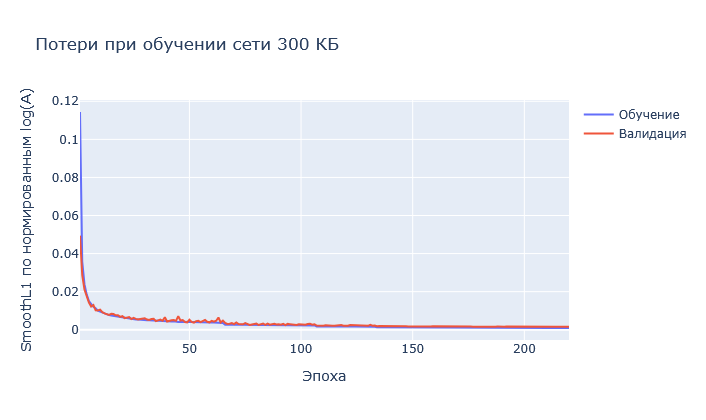

In [7]:
print('Режим: ПОЛНОЕ ОБУЧЕНИЕ С НУЛЯ. Старые веса не загружаются.')
train_info = ml_train(
    X, Y_target,
    epochs=ML_TRAIN_EPOCHS,
    batch_size=ML_BATCH_SIZE,
    patience=ML_TRAIN_PATIENCE,
    lr=ML_TRAIN_LR,
    seed=ML_SEED,
    model_path=ML_MODEL_FILE,
    output_max=ML_A_MAX,
    margin=ML_MARGIN,
)
ml_plot_training(train_info['history'])


## 6. Независимая оценка точности и равновесия

Оцениваются ошибки относительно исходных площадей НДМ и относительно целевых площадей с запасом `ML_MARGIN`, а также доля прогнозов с подтверждённым равновесием. Неподтверждённое равновесие не равнозначно доказанной недостаточности армирования.

Проверка выполняется с собственными `Rs` и `Rsc` каждого тестового образца.


In [8]:
tr,va,te=ml_split_indices(len(X),seed=ML_SEED)
Y_pred=ml_predict(X[te],ML_MODEL_FILE)
ml_metrics(Y_reference[te],Y_pred,title=f'Ошибка относительно эталона БЕЗ запаса, {len(te)} примеров')
ml_metrics(Y_target[te],Y_pred,title=f'Ошибка относительно целевого армирования с запасом, {len(te)} примеров')
ml_verify_predictions(X[te],Y_pred,limit=min(500,len(te)))
print('Средний фактический запас относительно эталона, %:',
      np.round(100*np.mean((Y_pred/Y_reference[te]-1),axis=0),3))
print('Модель:',ML_MODEL_FILE,'|',round(Path(ML_MODEL_FILE).stat().st_size/1024,1),'КиБ')
print('Для расчётного армирования итоговый прогноз обязательно проверять НДМ.')

Ошибка относительно эталона БЕЗ запаса, 50000 примеров
  MAE_sb: 0.93093
  MAE_st: 0.92305
  MAE_total: 1.817
  p95_max_abs_error: 4.9086
  p99_max_abs_error: 7.7777
  underprediction_rows_pct: 9.558
  median_total_excess: 1.085
Ошибка относительно целевого армирования с запасом, 50000 примеров
  MAE_sb: 0.30131
  MAE_st: 0.30828
  MAE_total: 0.51503
  p95_max_abs_error: 2.0202
  p99_max_abs_error: 4.9384
  underprediction_rows_pct: 81.598
  median_total_excess: -0.023092
Прогнозы с найденным допустимым равновесием: 433/500 (86.6%). Остальные — НЕ ПОДТВЕРЖДЕНЫ, а не доказанно небезопасны.
Средний фактический запас относительно эталона, %: [2.926 2.971]
Модель: ndm_mlp_300kb.npz | 289.6 КиБ
Для расчётного армирования итоговый прогноз обязательно проверять НДМ.


## 7. Пример: прогноз и проверка НДМ для заданного сечения

Отредактируй девять исходных параметров ниже. Модель загружается один раз;
`ml_predict` возвращает площади **в см²/м**, уже с запасом, заложенным при обучении.

Проверка `_ml_equilibrium_newton` решает задачу равновесия при фиксированных площадях;
`ПОДТВЕРЖДЕНО` означает наличие найденного допустимого деформационного состояния,
`НЕ ПОДТВЕРЖДЕНО` не доказывает недостаточности арматуры (потребуется более устойчивый контрольный решатель).


In [9]:
# Один заданный набор: [N (кН/м), My (кН·м/м), Rb (МПа), Eb (МПа),
#                      h (мм), a_sb (мм), a_st (мм), Rs (МПа), Rsc (МПа)]
# Изменяй эти значения на свои. Здесь: бетон B30, сталь A500.
CASE = np.array([
     250.0,    # N, кН/м
      30.0,    # My, кН·м/м
      17.0,    # Rb, МПа (B30)
   32500.0,    # Eb, МПа (B30)
     200.0,    # h, мм
      25.0,    # a_sb, мм
      25.0,    # a_st, мм
     435.0,    # Rs, МПа (A500)
     400.0,    # Rsc, МПа (A500, кратковременная нагрузка)
], dtype=np.float64)

# Кэшированная загрузка для последующих обращений: не перечитывать файл для каждого КЭ.
weights = ml_load_weights(ML_MODEL_FILE)
Asb, Ast = ml_predict(CASE, model_path=weights)
print(f'Прогноз: A_sb={Asb:.4f} см²/м, A_st={Ast:.4f} см²/м')

# Независимая проверка равновесия с предсказанным армированием.
flag, eps0, kappa, err = _ml_equilibrium_newton(CASE, float(Asb), float(Ast))
if flag == 1:
    n_check, m_check = predict_resultants(
        eps0, kappa, float(Asb), float(Ast),
        Rb=CASE[2], Eb=CASE[3], h=CASE[4], a_sb=CASE[5], a_st=CASE[6],
        Rs=CASE[7], Rsc=CASE[8], Es=ML_ES, es2=ML_ES2,
        eb0=ML_EB0, eb2=ML_EB2,
    )
    print('НДМ: ПОДТВЕРЖДЕНО допустимое равновесие')
    print(f'eps0={eps0:.9g}; kappa={kappa:.9g} 1/мм')
    print(f'N_расч={n_check/1e3:.6f} кН/м (задано {CASE[0]:.6f})')
    print(f'My_расч={m_check/1e6:.6f} кН·м/м (задано {CASE[1]:.6f})')
    print(f'Невязки: ΔN={(n_check/1e3-CASE[0]):.6g} кН/м, '
          f'ΔMy={(m_check/1e6-CASE[1]):.6g} кН·м/м')
else:
    print('НДМ: НЕ ПОДТВЕРЖДЕНО — проверочный Ньютон не нашёл допустимого равновесия.')
    print(f'Минимальная нормированная невязка = {err:.5g}')
    print('Это не доказательство нарушения прочности; используйте резервный решатель.')


Прогноз: A_sb=7.3656 см²/м, A_st=0.5243 см²/м
НДМ: ПОДТВЕРЖДЕНО допустимое равновесие
eps0=0.00112527745; kappa=-1.3631503e-05 1/мм
N_расч=250.000001 кН/м (задано 250.000000)
My_расч=30.000000 кН·м/м (задано 30.000000)
Невязки: ΔN=9.45393e-07 кН/м, ΔMy=-7.80461e-08 кН·м/м
